# Structural predictor: evaluation of each scoring component

The structural model predicts a player's points as the sum of expected points per FPL scoring action, each from its own
model (`structural/src/structural.py`, `predict`):

| Component | Column | Points | Model |
|---|---|---|---|
| Appearance | `e_app` | 1 for 1-59 min, 2 for 60+ | minutes state (0 / 1-59 / 60+), pooled over positions, with FPL's pre-deadline status |
| Clean sheet | `e_cs` | GK/DEF 4, MID 1, if on for 60+ | P(60+) × team's P(0 goals conceded) = e^(−λ), λ from a team goals-against model |
| Goals conceded | `e_gc` | GK/DEF −1 per 2 conceded | E[floor(GA/2)] with GA ~ Poisson(λ), shorter exposure for 1-59 min |
| Goals | `e_goals` | GK/DEF 6, MID 5, FWD 4 | Poisson GLM on xG per appearance, rescaled to realised goals, with set-piece duties |
| Assists | `e_assists` | 3 | Poisson GLM on xA, rescaled to realised assists |
| Bonus | `e_bonus` | 0-3 | Poisson GLM per position, capped at 3 |
| Saves | `e_saves` | GK 1 per 3 saves | E[floor(S/3)] with S ~ Poisson |
| Other | `e_other` | +5 penalty saved, −1 yellow, −3 red, −2 own goal, −2 penalty missed | constant mean per appearance |

Each component's expected points are weighted by P(1-59 min) and P(60+), so they sum to `pred`.

**What is evaluated here.** For every player-fixture, the actual points of each component are rebuilt from the FPL
counts (minutes, goals, assists, clean sheets, goals conceded, saves, bonus, cards, …) with the same scoring rules;
they add up to `total_points` exactly (checked below). Each `e_*` is then scored against its actual component:

1. **Level:** mean predicted against mean actual points per component and position.
2. **Accuracy:** RMSE, R² and Spearman per component, and the skill over a simple baseline (the player's mean points
   from that component in the season so far).
3. **Where the error comes from:** each component's share of the total prediction error.
4. **The probabilities behind the components:** playing, playing 60+, the team's clean sheet and goals conceded.
5. **Calibration given that the player plays:** each component's expected points if the player plays (`e_* / p_play`)
   against what players who played scored from it.

**Data.** The deployed structural predictions (trained with the previous season:
`outputs/{season}/structural_predictions_history_{prev}.csv`), one row per player and fixture, gameweeks 5-38, every
player with a fixture. This matches the structural README's tables.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import poisson, spearmanr
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "structural" / "src").exists())
STRUCT = ROOT / "structural"
SEASONS = {
    "23-24": "22-23",
    "24-25": "23-24",
}  # season: history season it was trained with
FIRST_GW = 5
POS = ["GK", "DEF", "MID", "FWD"]

# FPL scoring (structural.SCORING), the same in both seasons
SCORING = {
    "GK": {"goal": 6, "cs": 4, "gc_per2": 1, "save_per3": 1},
    "DEF": {"goal": 6, "cs": 4, "gc_per2": 1, "save_per3": 0},
    "MID": {"goal": 5, "cs": 1, "gc_per2": 0, "save_per3": 0},
    "FWD": {"goal": 4, "cs": 0, "gc_per2": 0, "save_per3": 0},
}
COMP = ["app", "cs", "gc", "goals", "assists", "bonus", "saves", "other"]
NAME = {
    "app": "Appearance",
    "cs": "Clean sheet",
    "gc": "Goals conceded",
    "goals": "Goals",
    "assists": "Assists",
    "bonus": "Bonus",
    "saves": "Saves",
    "other": "Other",
}
# which positions each component applies to (it is 0 for the others)
APPLIES = {
    "app": POS,
    "cs": ["GK", "DEF", "MID"],
    "gc": ["GK", "DEF"],
    "goals": POS,
    "assists": POS,
    "bonus": POS,
    "saves": ["GK"],
    "other": POS,
}

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#8a8f98", "#22252b"
SEASON_COLOR = {"23-24": BLUE, "24-25": ORANGE}
SEASON_STYLE = {
    "23-24": {"ls": "-", "marker": "o"},
    "24-25": {"ls": "--", "marker": "s"},
}
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 9,
        "axes.titlesize": 9,
        "axes.labelsize": 9,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#5b6068",
        "axes.grid": True,
        "grid.color": "#e3e5e8",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.6,
        "lines.markersize": 3,
        "figure.dpi": 120,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
FIG = ROOT / "working/figures"  # the thesis figures (PDF)
FIG.mkdir(exist_ok=True)


def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")


## 1. Load the predictions and rebuild each component's actual points

In [2]:
COUNTS = [
    "goals_scored",
    "assists",
    "clean_sheets",
    "goals_conceded",
    "saves",
    "bonus",
    "penalties_saved",
    "yellow_cards",
    "red_cards",
    "own_goals",
    "penalties_missed",
    "was_home",
    "team_h_score",
    "team_a_score",
    "expected_goals",
    "expected_assists",
]


def actual_components(d):
    s = pd.DataFrame([SCORING[p] for p in d["pos"]], index=d.index)
    m = d["minutes"]
    return pd.DataFrame(
        {
            "app": np.select([m >= 60, m > 0], [2, 1], 0),
            "cs": s["cs"] * d["clean_sheets"] * (m >= 60),
            "gc": -s["gc_per2"] * (d["goals_conceded"] // 2),
            "goals": s["goal"] * d["goals_scored"],
            "assists": 3 * d["assists"],
            "bonus": d["bonus"],
            "saves": s["save_per3"] * (d["saves"] // 3),
            "other": 5 * d["penalties_saved"]
            - d["yellow_cards"]
            - 3 * d["red_cards"]
            - 2 * d["own_goals"]
            - 2 * d["penalties_missed"],
        },
        index=d.index,
    )


def load(season):
    pred = pd.read_csv(
        STRUCT
        / f"outputs/{season}/structural_predictions_history_{SEASONS[season]}.csv"
    )
    pred = pred[(pred["round"] >= FIRST_GW) & pred["has_target"]]
    raw = pd.read_csv(
        STRUCT / f"data/{season}/players.csv.gz",
        usecols=["fpl_id", "round", "fixture"] + COUNTS,
        low_memory=False,
    )
    d = pred.merge(raw, on=["fpl_id", "round", "fixture"], how="left", validate="1:1")
    assert d["goals_scored"].notna().all(), "a prediction has no row in players.csv"
    a = actual_components(d)
    assert (a.sum(axis=1) == d["total_points"]).all(), (
        "components don't add up to total_points"
    )
    assert np.allclose(d[[f"e_{c}" for c in COMP]].sum(axis=1), d["pred"])
    for c in COMP:
        d[c] = a[c]
    d["team_ga"] = np.where(
        d["was_home"], d["team_a_score"], d["team_h_score"]
    )  # team's goals conceded
    d["season"] = season
    return d.reset_index(drop=True)


data = {s: load(s) for s in SEASONS}
pd.DataFrame(
    {
        s: {
            "player-fixtures": len(d),
            "gameweeks": d["round"].nunique(),
            "share who played": d["played"].mean(),
            "share 60+": (d["minutes"] >= 60).mean(),
            "components add up to total_points": "yes (checked)",
        }
        for s, d in data.items()
    }
)

,23-24,24-25
player-fixtures,27084,24733
gameweeks,34,34
share who played,0.377,0.418
share 60+,0.26,0.283
components add up to total_points,yes (checked),yes (checked)


## 2. Level: mean predicted vs mean actual points per component

Mean points per player-fixture, every player with a fixture. `ratio` = predicted / actual. A component that is 0 for a
position by the rules (e.g. saves for outfield players) is left blank.

In [3]:
rows = []
for season, d in data.items():
    for pos in POS + ["All"]:
        x = d if pos == "All" else d[d["pos"] == pos]
        for c in COMP + ["total"]:
            if pos != "All" and c != "total" and pos not in APPLIES[c]:
                continue
            p = x["pred"] if c == "total" else x[f"e_{c}"]
            y = x["total_points"] if c == "total" else x[c]
            rows.append(
                {
                    "season": season,
                    "pos": pos,
                    "component": "Total" if c == "total" else NAME[c],
                    "predicted": p.mean(),
                    "actual": y.mean(),
                }
            )
level = pd.DataFrame(rows)
level["ratio"] = level["predicted"] / level["actual"].where(
    level["actual"].abs() > 1e-9
)
order = [NAME[c] for c in COMP] + ["Total"]
(
    level.pivot_table(
        index=["season", "component"],
        columns="pos",
        values=["predicted", "actual"],
        sort=False,
    )
    .reindex(columns=POS + ["All"], level=1)
    .reindex(pd.MultiIndex.from_product([SEASONS, order]))
)

predicted                                 actual                            
pos                         GK    DEF    MID    FWD    All         GK    DEF    MID    FWD    All
23-24 Appearance         0.451  0.692  0.648  0.576  0.630  4.422e-01  0.701  0.660  0.574  0.637
      Clean sheet        0.201  0.278  0.057    NaN  0.138  1.843e-01  0.271  0.068    NaN  0.138
      Goals conceded    -0.124 -0.174    NaN    NaN -0.070 -1.273e-01 -0.182    NaN    NaN -0.073
      Goals              0.000  0.090  0.253  0.367  0.186  0.000e+00  0.098  0.257  0.371  0.191
      Assists            0.002  0.070  0.154  0.132  0.106  1.934e-03  0.074  0.152  0.126  0.106
      Bonus              0.063  0.074  0.082  0.140  0.085  6.220e-02  0.070  0.081  0.121  0.081
      Saves              0.152    NaN    NaN    NaN  0.017  1.650e-01    NaN    NaN    NaN  0.019
      Other             -0.002 -0.073 -0.063 -0.046 -0.057 -1.225e-02 -0.075 -0.067 -0.047 -0.061
      Total              0.743  0.957  1.131  1.170  1.035  7.161e-01  0.957  1.152  1.144  1.038
24-25 Appearance         0.541  0.736  0.749  0.668  0.714  5.246e-01  0.722  0.738  0.651  0.701
      Clean sheet        0.253  0.302  0.068    NaN  0.159  2.433e-01  0.302  0.079    NaN  0.163
      Goals conceded    -0.141 -0.177    NaN    NaN -0.074 -1.359e-01 -0.166    NaN    NaN -0.070
      Goals              0.000  0.097  0.274  0.443  0.204  0.000e+00  0.086  0.256  0.427  0.191
      Assists            0.005  0.072  0.165  0.142  0.114  1.155e-02  0.063  0.160  0.118  0.107
      Bonus              0.068  0.067  0.094  0.169  0.090  5.004e-02  0.062  0.090  0.186  0.087
      Saves              0.190    NaN    NaN    NaN  0.020  1.751e-01    NaN    NaN    NaN  0.018
      Other             -0.009 -0.081 -0.078 -0.053 -0.069  3.849e-04 -0.073 -0.070 -0.049 -0.061
      Total              0.907  1.016  1.272  1.370  1.158  8.691e-01  0.996  1.253  1.332  1.135

In [4]:
# the same, for every position together, with the ratio
(
    level[level["pos"] == "All"]
    .pivot_table(
        index="component",
        columns="season",
        values=["predicted", "actual", "ratio"],
        sort=False,
    )
    .reindex(order)
)

predicted        actual         ratio       
season             23-24  24-25  23-24  24-25  23-24  24-25
component                                                  
Appearance         0.630  0.714  0.637  0.701  0.989  1.019
Clean sheet        0.138  0.159  0.138  0.163  0.996  0.975
Goals conceded    -0.070 -0.074 -0.073 -0.070  0.959  1.060
Goals              0.186  0.204  0.191  0.191  0.973  1.071
Assists            0.106  0.114  0.106  0.107  1.001  1.067
Bonus              0.085  0.090  0.081  0.087  1.052  1.038
Saves              0.017  0.020  0.019  0.018  0.923  1.083
Other             -0.057 -0.069 -0.061 -0.061  0.938  1.119
Total              1.035  1.158  1.038  1.135  0.997  1.020

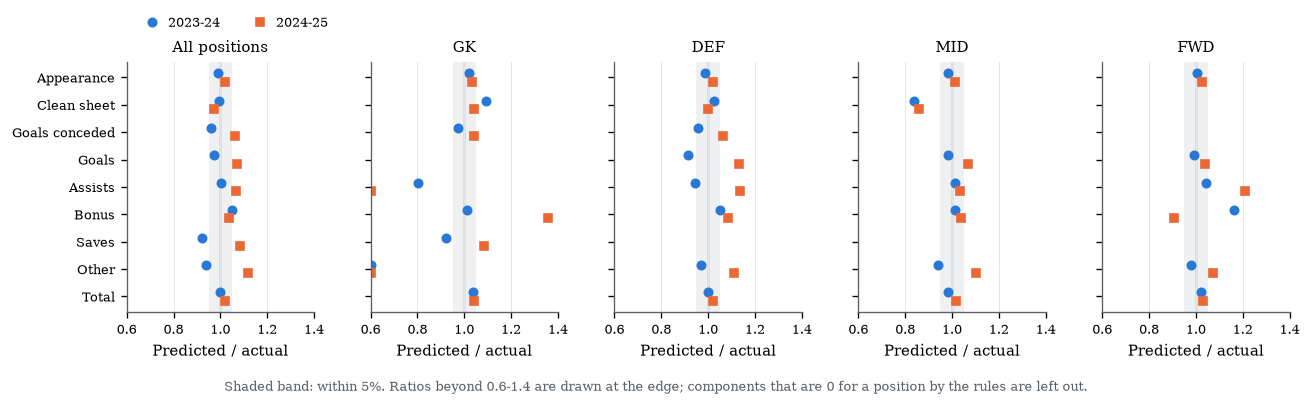

In [5]:
# Figure: predicted / actual mean per component, overall and by position (1 = right on average)
fig, axes = plt.subplots(1, 5, figsize=(11, 3.2), sharey=True)
ypos = {c: i for i, c in enumerate(order[::-1])}
for ax, pos in zip(axes, ["All"] + POS):
    ax.axvspan(0.95, 1.05, color="#eef0f2", zorder=0, lw=0)
    ax.axvline(1, color=GREY, lw=0.8, zorder=1)
    for k, season in enumerate(SEASONS):
        x = level[(level["season"] == season) & (level["pos"] == pos)].dropna(subset=["ratio"])
        ax.plot(x["ratio"].clip(0.6, 1.4), [ypos[c] + (0.15 if k == 0 else -0.15) for c in x["component"]],
                ls="none", marker=SEASON_STYLE[season]["marker"], ms=5, color=SEASON_COLOR[season],
                label=f"20{season}", zorder=2)
    ax.set_xlim(0.6, 1.4)
    ax.set_title("All positions" if pos == "All" else pos)
    ax.set_xlabel("Predicted / actual")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(list(ypos.values()), list(ypos.keys()))
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, handletextpad=0.2)
fig.text(0.5, -0.04, "Shaded band: within 5%. Ratios beyond 0.6-1.4 are drawn at the edge; components that are 0 for a "
         "position by the rules are left out.", ha="center", fontsize=8, color="#5b6068")
fig.tight_layout()
save(fig, "structural_level")
plt.show()


## 3. Accuracy per component

Every player with a fixture. R² is against the component's overall mean (so it says how much of the component's
variation the model explains), and **skill** = 1 − MSE / MSE of the baseline, where the baseline is the player's mean
points from that component per fixture in the season so far (0 before his first fixture). Positive skill means the model
beats that baseline.

In [6]:
def baseline(d, col):
    # the player's mean of col per fixture in earlier gameweeks of the season (walk-forward)
    g = (
        d.groupby(["fpl_id", "round"])[col]
        .agg(["sum", "size"])
        .reset_index()
        .sort_values("round")
    )
    g[["csum", "cn"]] = (
        g.groupby("fpl_id")[["sum", "size"]].cumsum() - g[["sum", "size"]].values
    )
    g["base"] = (g["csum"] / g["cn"].replace(0, np.nan)).fillna(0.0)
    return (
        d[["fpl_id", "round"]]
        .merge(g[["fpl_id", "round", "base"]], on=["fpl_id", "round"], how="left")[
            "base"
        ]
        .values
    )


def full_history(season):
    # every gameweek from 1, so the baseline has the season's earlier gameweeks too
    pred = pd.read_csv(
        STRUCT
        / f"outputs/{season}/structural_predictions_history_{SEASONS[season]}.csv"
    )
    raw = pd.read_csv(
        STRUCT / f"data/{season}/players.csv.gz",
        usecols=["fpl_id", "round", "fixture"] + COUNTS,
        low_memory=False,
    )
    d = pred.merge(raw, on=["fpl_id", "round", "fixture"], how="left", validate="1:1")
    a = actual_components(d)
    for c in COMP:
        d[c] = a[c]
    return d


@np.errstate(
    divide="ignore", invalid="ignore"
)  # GK goals: no goals scored, so no variance
def acc(y, p, b):
    e = p - y
    sst = ((y - y.mean()) ** 2).sum()
    return {
        "RMSE": np.sqrt((e**2).mean()),
        "R2": 1 - (e**2).sum() / sst if sst > 0 else np.nan,
        "Spearman": spearmanr(p, y)[0] if y.nunique() > 1 else np.nan,
        "baseline RMSE": np.sqrt(((b - y) ** 2).mean()),
        "skill": 1 - (e**2).mean() / ((b - y) ** 2).mean(),
    }


rows = []
for season, d in data.items():
    h = full_history(season)
    for c in COMP + ["total_points"]:
        h[f"b_{c}"] = baseline(h, c)
    d = d.merge(
        h[["fpl_id", "round", "fixture"] + [f"b_{c}" for c in COMP + ["total_points"]]],
        on=["fpl_id", "round", "fixture"],
        how="left",
        validate="1:1",
    )
    data[season] = d
    for c in COMP + ["total"]:
        y = d["total_points"] if c == "total" else d[c]
        p = d["pred"] if c == "total" else d[f"e_{c}"]
        b = d["b_total_points"] if c == "total" else d[f"b_{c}"]
        rows.append(
            {
                "season": season,
                "component": "Total" if c == "total" else NAME[c],
                **acc(y, p, b),
            }
        )
accuracy = pd.DataFrame(rows).set_index(["season", "component"])
accuracy

RMSE     R2  Spearman  baseline RMSE  skill
season component                                                   
23-24  Appearance      0.465  0.712     0.786          0.610  0.418
       Clean sheet     0.608  0.169     0.296          0.640  0.098
       Goals conceded  0.253  0.322     0.419          0.278  0.168
       Goals           0.992  0.112     0.254          1.024  0.062
       Assists         0.582  0.085     0.232          0.603  0.070
       Bonus           0.408  0.080     0.256          0.422  0.062
       Saves           0.125  0.448     0.373          0.136  0.155
       Other           0.272  0.065     0.256          0.285  0.086
       Total           1.850  0.344     0.723          2.001  0.145
24-25  Appearance      0.486  0.695     0.795          0.609  0.364
       Clean sheet     0.655  0.171     0.310          0.694  0.109
       Goals conceded  0.248  0.285     0.410          0.269  0.149
       Goals           0.972  0.113     0.256          1.005  0.065
       Assists         0.581  0.073     0.225          0.601  0.064
       Bonus           0.420  0.095     0.258          0.433  0.057
       Saves           0.122  0.413     0.391          0.134  0.180
       Other           0.294  0.051     0.246          0.306  0.077
       Total           1.871  0.341     0.735          2.002  0.126

### By position (R² and skill)

In [7]:
rows = []
for season, d in data.items():
    for pos in POS:
        x = d[d["pos"] == pos]
        for c in COMP + ["total"]:
            if c != "total" and pos not in APPLIES[c]:
                continue
            y = x["total_points"] if c == "total" else x[c]
            p = x["pred"] if c == "total" else x[f"e_{c}"]
            b = x["b_total_points"] if c == "total" else x[f"b_{c}"]
            r = acc(y, p, b)
            rows.append(
                {
                    "season": season,
                    "pos": pos,
                    "component": "Total" if c == "total" else NAME[c],
                    "R2": r["R2"],
                    "skill": r["skill"],
                }
            )
(
    pd.DataFrame(rows)
    .pivot_table(
        index=["season", "component"], columns="pos", values=["R2", "skill"], sort=False
    )
    .reindex(columns=POS, level=1)
    .reindex(pd.MultiIndex.from_product([SEASONS, order]))
)

R2                       skill                     
pos                      GK    DEF    MID    FWD     GK    DEF    MID    FWD
23-24 Appearance      0.788  0.675  0.716  0.722  0.427  0.422  0.408  0.435
      Clean sheet     0.182  0.141  0.142    NaN  0.099  0.100  0.075    NaN
      Goals conceded  0.330  0.250    NaN    NaN  0.167  0.169    NaN    NaN
      Goals             NaN  0.025  0.109  0.140    NaN  0.069  0.056  0.073
      Assists         0.001  0.044  0.092  0.076  0.014  0.078  0.069  0.060
      Bonus           0.082  0.063  0.096  0.059  0.060  0.084  0.060  0.035
      Saves           0.388    NaN    NaN    NaN  0.155    NaN    NaN    NaN
      Other          -0.005  0.071  0.070  0.052  0.064  0.103  0.076  0.081
      Total           0.441  0.273  0.369  0.347  0.178  0.155  0.140  0.127
24-25 Appearance      0.780  0.664  0.683  0.756  0.403  0.359  0.341  0.453
      Clean sheet     0.170  0.145  0.137    NaN  0.100  0.112  0.096    NaN
      Goals conceded  0.275  0.216    NaN    NaN  0.175  0.143    NaN    NaN
      Goals             NaN  0.023  0.093  0.185    NaN  0.055  0.046  0.135
      Assists         0.004  0.039  0.074  0.062  0.022  0.052  0.066  0.078
      Bonus          -0.014  0.053  0.084  0.150  0.022  0.056  0.050  0.079
      Saves           0.337    NaN    NaN    NaN  0.180    NaN    NaN    NaN
      Other          -0.002  0.059  0.055  0.047  0.067  0.096  0.069  0.063
      Total           0.409  0.290  0.339  0.390  0.142  0.129  0.103  0.183

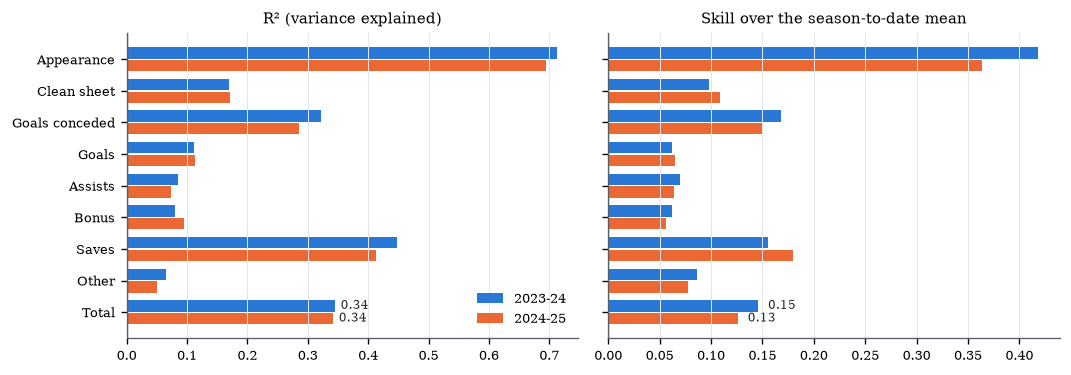

In [8]:
# Figure: R2 and skill over the player's season-to-date mean, per component
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
comps = order[::-1]
y = np.arange(len(comps))
h = 0.36
for ax, metric, title in zip(axes, ["R2", "skill"],
                             ["R² (variance explained)", "Skill over the season-to-date mean"]):
    for k, season in enumerate(SEASONS):
        v = accuracy.loc[season, metric].reindex(comps)
        ax.barh(y + (h / 2 + 0.02) * (1 if k == 0 else -1), v, height=h, color=SEASON_COLOR[season],
                label=f"20{season}")
        for yi, vi in zip(y, v):
            if comps[yi] == "Total":
                ax.text(vi + 0.01, yi + (h / 2 + 0.02) * (1 if k == 0 else -1), f"{vi:.2f}", va="center",
                        fontsize=7, color=INK)
    ax.axvline(0, color="#5b6068", lw=0.8)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, comps)
axes[0].legend(loc="lower right")
fig.tight_layout()
save(fig, "structural_accuracy")
plt.show()


## 4. Where the prediction error comes from

The total error (pred − points) is the sum of the component errors, so its variance splits exactly into
Σ_k cov(error_k, total error). Each component's share says how much of the total squared error it is responsible
for (shares add to 100%; a negative share means that component's errors partly cancel the others').

In [9]:
rows = []
for season, d in data.items():
    for pos in POS + ["All"]:
        x = d if pos == "All" else d[d["pos"] == pos]
        err = {c: x[f"e_{c}"] - x[c] for c in COMP}
        tot = sum(err.values())
        var = tot.var()
        for c in COMP:
            rows.append(
                {
                    "season": season,
                    "pos": pos,
                    "component": NAME[c],
                    "share": np.cov(err[c], tot)[0, 1] / var,
                }
            )
share = (
    pd.DataFrame(rows)
    .pivot_table(
        index=["season", "component"], columns="pos", values="share", sort=False
    )
    .reindex(columns=POS + ["All"])
    .reindex(pd.MultiIndex.from_product([SEASONS, [NAME[c] for c in COMP]]))
)
share.style.format("{:.1%}")

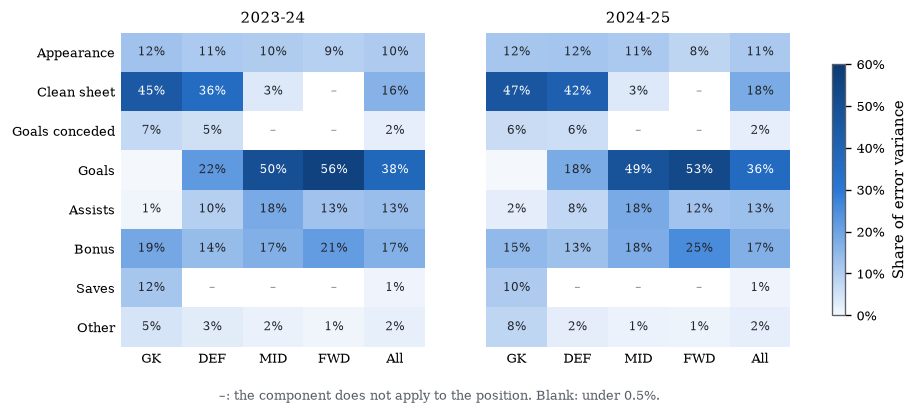

In [10]:
# Figure: each component's share of the total error variance, by position (columns add to 100%)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#2a78d6", "#0d3b73"])
cmap.set_bad("white")  # the component does not apply to the position
for ax, season in zip(axes, SEASONS):
    m = share.loc[season].copy()
    key = {v: k for k, v in NAME.items()}
    for comp in m.index:  # a component that does not apply to a position has no error there: show it as n/a
        for pos in POS:
            if pos not in APPLIES[key[comp]]:
                m.loc[comp, pos] = np.nan
    im = ax.imshow(m.clip(lower=0).to_numpy(), cmap=cmap, vmin=0, vmax=0.6, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            if not np.isfinite(v):
                ax.text(j, i, "–", ha="center", va="center", fontsize=7, color=GREY)
            elif abs(v) >= 0.005:
                ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                        color="white" if v > 0.3 else INK)
    ax.set_xticks(range(m.shape[1]), [c if c != "All" else "All" for c in m.columns])
    ax.set_yticks(range(m.shape[0]), m.index)
    ax.set_title(f"20{season}")
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, format=plt.matplotlib.ticker.PercentFormatter(1.0), label="Share of error variance")
fig.text(0.42, -0.02, "–: the component does not apply to the position. Blank: under 0.5%.", ha="center", fontsize=8,
         color="#5b6068")
save(fig, "structural_error_share")
plt.show()


## 5. The probabilities behind the components

* **Plays** (`p_play`) and **plays 60+** (`p60`), every player-fixture: they drive the appearance points and weight
  every other component.
* **Team clean sheet** (`p_cs` = e^(−λ)) and **team goals conceded** (`lam_ga` = λ), one row per team and fixture
  (every player of a team gets the same λ).

Brier score and log loss are lower-is-better; the "base rate" columns are the same scores for a constant prediction
equal to the overall rate, so the model should beat them. AUC is how well the probability separates the two outcomes
(0.5 = no better than chance).

In [11]:
def binary(y, p):
    rate = y.mean()
    return {
        "rows": len(y),
        "mean predicted": p.mean(),
        "observed rate": rate,
        "Brier": brier_score_loss(y, p),
        "Brier, base rate": brier_score_loss(y, np.full(len(y), rate)),
        "log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]),
        "log loss, base rate": log_loss(y, np.full(len(y), rate), labels=[0, 1]),
        "AUC": roc_auc_score(y, p),
    }


def team_rows(d):
    return d.drop_duplicates(["team", "fixture"])[
        ["team", "fixture", "round", "lam_ga", "p_cs", "team_ga"]
    ]


rows, teams = [], {}
for season, d in data.items():
    t = teams[season] = team_rows(d)
    rows.append(
        {
            "season": season,
            "event": "Plays",
            **binary(d["played"].astype(int), d["p_play"]),
        }
    )
    rows.append(
        {
            "season": season,
            "event": "Plays 60+",
            **binary((d["minutes"] >= 60).astype(int), d["p60"]),
        }
    )
    rows.append(
        {
            "season": season,
            "event": "Team clean sheet",
            **binary((t["team_ga"] == 0).astype(int), t["p_cs"]),
        }
    )
events = pd.DataFrame(rows).set_index(["season", "event"])
display(events)

rows = []
for season, t in teams.items():
    lam, y = t["lam_ga"], t["team_ga"]
    dev = (
        2
        * (
            np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / lam), 0) - (y - lam)
        ).mean()
    )
    dev0 = (
        2
        * (
            np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / y.mean()), 0)
            - (y - y.mean())
        ).mean()
    )
    rows.append(
        {
            "season": season,
            "team-fixtures": len(t),
            "mean λ": lam.mean(),
            "mean goals conceded": y.mean(),
            "Poisson deviance": dev,
            "deviance, constant": dev0,
            "deviance explained": 1 - dev / dev0,
            "P(0) predicted": t["p_cs"].mean(),
            "P(0) observed": (y == 0).mean(),
            "P(4+) predicted": poisson.sf(3, lam).mean(),
            "P(4+) observed": (y >= 4).mean(),
        }
    )
pd.DataFrame(rows).set_index("season")

rows  mean predicted  observed rate  Brier  Brier, base rate  log loss  log loss, base rate    AUC
season event                                                                                                                
23-24  Plays             27084           0.372          0.377  0.075             0.235     0.248                0.663  0.960
       Plays 60+         27084           0.259          0.260  0.073             0.192     0.236                0.573  0.955
       Team clean sheet    682           0.225          0.210  0.157             0.166     0.484                0.514  0.673
24-25  Plays             24733           0.425          0.418  0.081             0.243     0.265                0.680  0.955
       Plays 60+         24733           0.289          0.283  0.083             0.203     0.263                0.595  0.947
       Team clean sheet    680           0.235          0.235  0.171             0.180     0.519                0.546  0.650

,team-fixtures,mean λ,mean goals conceded,Poisson deviance,"deviance, constant",deviance explained,P(0) predicted,P(0) observed,P(4+) predicted,P(4+) observed
season,,,,,,,,,,
23-24,682,1.586,1.641,1.097,1.244,0.119,0.225,0.210,0.088,0.095
24-25,680,1.538,1.484,1.086,1.201,0.095,0.235,0.235,0.082,0.075


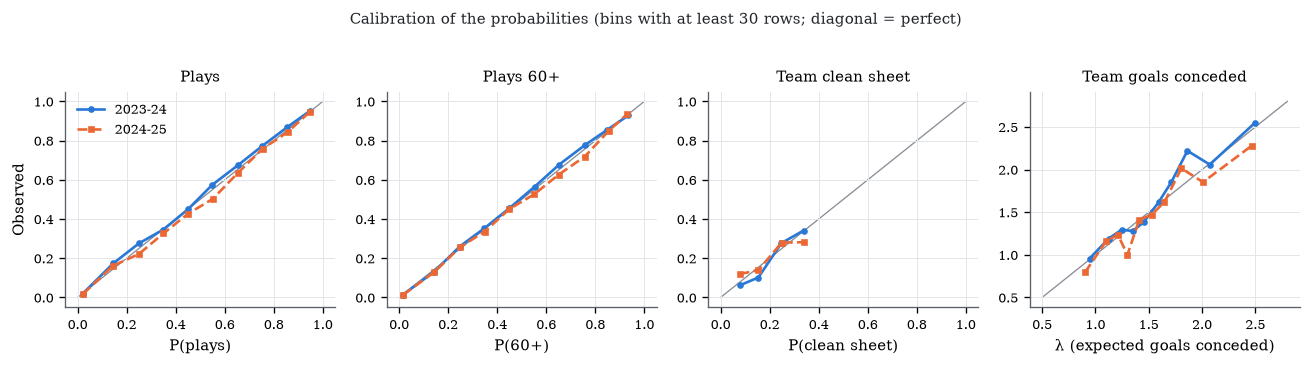

In [12]:
def calib(ax, p, y, bins, season, label=None):
    b = pd.cut(p, bins, include_lowest=True)
    c = (
        pd.DataFrame({"p": p, "y": y})
        .groupby(b, observed=True)
        .agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    )
    c = c[c["n"] >= 30]
    ax.plot(
        c["p"],
        c["y"],
        color=SEASON_COLOR[season],
        label=label or f"20{season}",
        **SEASON_STYLE[season],
    )


fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
pb = np.linspace(0, 1, 11)
for season, d in data.items():
    t = teams[season]
    calib(axes[0], d["p_play"], d["played"].astype(int), pb, season)
    calib(axes[1], d["p60"], (d["minutes"] >= 60).astype(int), pb, season)
    calib(axes[2], t["p_cs"], (t["team_ga"] == 0).astype(int), pb, season)
    calib(
        axes[3],
        t["lam_ga"],
        t["team_ga"],
        np.quantile(t["lam_ga"], np.linspace(0, 1, 11)),
        season,
    )
for ax, title, lab in zip(
    axes,
    ["Plays", "Plays 60+", "Team clean sheet", "Team goals conceded"],
    ["P(plays)", "P(60+)", "P(clean sheet)", "λ (expected goals conceded)"],
):
    lim = [0, 1] if ax is not axes[3] else [0.5, 2.8]
    ax.plot(lim, lim, color=GREY, lw=0.8, zorder=0)
    ax.set_title(title)
    ax.set_xlabel(lab)
axes[0].set_ylabel("Observed")
axes[0].legend(loc="upper left")
fig.suptitle(
    "Calibration of the probabilities (bins with at least 30 rows; diagonal = perfect)",
    y=1.03,
    fontsize=9,
    color=INK,
)
fig.tight_layout()
save(fig, "structural_probabilities")
plt.show()

## 6. Calibration of each component, given that the player plays

Each component's expected points are weighted by P(1-59) or P(60+), so `e_* / p_play` is exactly the expected points
from that component **if the player plays**. Among the players who played, these are binned (10 equal-sized bins of
each component's conditional prediction, per season) and compared with what they actually scored from that component.
This separates the component models from the minutes model: a component can be right on average over everyone only
because its playing-time errors cancel.

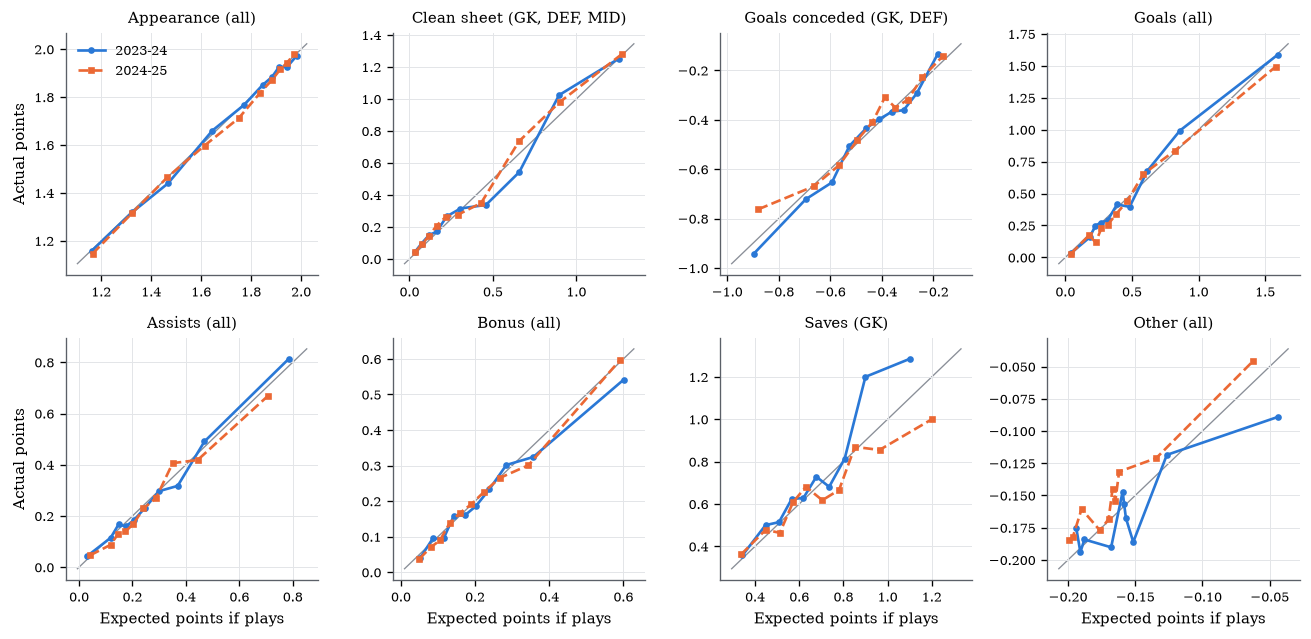

rows  predicted | plays  actual | played  top decile predicted  top decile actual  Spearman | played
season component                                                                                                            
23-24  Appearance      10208              1.694            1.690                 1.981              1.972              0.557
       Clean sheet      8915              0.418            0.420                 1.253              1.251              0.185
       Goals conceded   4133             -0.470           -0.481                -0.182             -0.133              0.328
       Goals           10208              0.498            0.507                 1.595              1.587              0.251
       Assists         10208              0.285            0.282                 0.786              0.814              0.199
       Bonus           10208              0.225            0.214                 0.601              0.542              0.204
       Saves             698              0.671            0.734                 1.102              1.286              0.325
       Other           10208             -0.154           -0.161                -0.044             -0.089              0.046
24-25  Appearance      10335              1.687            1.676                 1.973              1.980              0.564
       Clean sheet      9196              0.416            0.437                 1.276              1.283              0.200
       Goals conceded   4079             -0.448           -0.426                -0.162             -0.142              0.302
       Goals           10335              0.487            0.457                 1.579              1.493              0.257
       Assists         10335              0.272            0.257                 0.709              0.670              0.187
       Bonus           10335              0.214            0.208                 0.590              0.596              0.208
       Saves             689              0.700            0.660                 1.200              1.000              0.258
       Other           10335             -0.162           -0.147                -0.062             -0.045              0.067

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.4))
rows = []
for season, d in data.items():
    x = d[d["played"]]
    for ax, c in zip(axes.ravel(), COMP):
        x_c = x[x["pos"].isin(APPLIES[c])]
        p = x_c[f"e_{c}"] / x_c["p_play"].clip(lower=1e-6)
        y = x_c[c]
        b = pd.qcut(p.rank(method="first"), 10, labels=False)
        cal = pd.DataFrame({"p": p, "y": y}).groupby(b).mean()
        ax.plot(
            cal["p"],
            cal["y"],
            color=SEASON_COLOR[season],
            label=f"20{season}",
            **SEASON_STYLE[season],
        )
        top = b == 9
        rows.append(
            {
                "season": season,
                "component": NAME[c],
                "rows": len(y),
                "predicted | plays": p.mean(),
                "actual | played": y.mean(),
                "top decile predicted": p[top].mean(),
                "top decile actual": y[top].mean(),
                "Spearman | played": spearmanr(p, y)[0],
            }
        )
for ax, c in zip(axes.ravel(), COMP):
    lo, hi = ax.get_xlim()
    lo, hi = min(lo, ax.get_ylim()[0]), max(hi, ax.get_ylim()[1])
    ax.plot([lo, hi], [lo, hi], color=GREY, lw=0.8, zorder=0)
    ax.set_title(f"{NAME[c]} ({', '.join(APPLIES[c]) if APPLIES[c] != POS else 'all'})")
for ax in axes[1]:
    ax.set_xlabel("Expected points if plays")
for ax in axes[:, 0]:
    ax.set_ylabel("Actual points")
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
save(fig, "structural_conditional_calibration")
plt.show()
cond = pd.DataFrame(rows).set_index(["season", "component"])
cond

## 7. The goal and assist models on their own outcomes

Sections 2-6 score each component in points, which mixes the event model with the minutes model and the scoring
rules. Here the goal and assist models are scored on the events themselves, among the player-fixtures in which the
player played:

* **Expected count given that he plays:** `rate = e_k / (points per event × p_play)` (goals: 6 GK/DEF, 5 MID, 4 FWD;
  assists: 3). It averages over 1-59 and 60+ minutes.
* **P(at least one) = 1 − e^(−rate)** (the models are Poisson), scored with the Brier score, log loss and AUC against
  two baselines: the overall rate, and the **player's own rate per appearance in the season so far** (walk-forward), shrunk to his position's
  rate with the weight of 10 appearances (a raw rate after one appearance is 0 or 1).
* **Poisson deviance of the count** for the model and both baselines.
* **Model or finishing?** The goal and assist models are fitted on FPL's xG and xA and then rescaled to realised counts
  (`structural.Scaled`). The squared correlation of the predicted rate with the player's realised xG (xA), against
  that with his realised goals (assists), shows how much of the shortfall is the model and how much is whether the
  chance went in. Correlation does not depend on the rescaling factor, which is not stored.


In [14]:
# counts (the "assists" column holds assist points by now, so the count is rebuilt as n_assists)
EVENTS = {"goals": ("goals_scored", "expected_goals", "Goals"), "assists": ("n_assists", "expected_assists", "Assists")}
SHRINK = 10  # the player-rate baseline is shrunk to his position's rate with the weight of 10 appearances
GOAL_PTS = {p: SCORING[p]["goal"] for p in POS}


def player_rate(season, count):
    """The player's count per appearance in earlier gameweeks of the season (walk-forward), shrunk to his position's
    rate per appearance over the season with the weight of SHRINK appearances (his position's rate before his first)."""
    h = full_history(season)
    h = h[h["played"]].assign(n_assists=lambda z: z["assists"] / 3)
    pos_rate = h.groupby("pos")[count].mean()
    g = h.groupby(["fpl_id", "round", "pos"])[count].agg(["sum", "size"]).reset_index().sort_values("round")
    g[["csum", "cn"]] = g.groupby("fpl_id")[["sum", "size"]].cumsum() - g[["sum", "size"]].values
    g["rate"] = (g["csum"] + SHRINK * g["pos"].map(pos_rate)) / (g["cn"] + SHRINK)
    return g[["fpl_id", "round", "rate"]]


def poisson_dev(y, mu):
    mu = np.clip(mu, 1e-9, None)
    return 2 * np.mean(np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))


played, rows, xrows = {}, [], []
for season, d in data.items():
    x = d[d["played"]].assign(n_assists=lambda z: z["assists"] / 3)
    for k, (count, xcol, name) in EVENTS.items():
        pts = x["pos"].map(GOAL_PTS) if k == "goals" else 3
        x[f"rate_{k}"] = x[f"e_{k}"] / (pts * x["p_play"].clip(lower=1e-6))
        r = player_rate(season, count).rename(columns={"rate": f"base_{k}"})
        x = x.merge(r, on=["fpl_id", "round"], how="left")
        x[f"base_{k}"] = x[f"base_{k}"].fillna(x[count].mean())  # no earlier appearance in the whole history
        y = x[count].to_numpy()
        hit = (y >= 1).astype(int)
        p = 1 - np.exp(-x[f"rate_{k}"].to_numpy())
        pb = 1 - np.exp(-x[f"base_{k}"].to_numpy())
        rows.append({"season": season, "event": name, "rows": len(x),
                     "P(≥1) predicted": p.mean(), "P(≥1) observed": hit.mean(),
                     "Brier": brier_score_loss(hit, p),
                     "Brier, player rate": brier_score_loss(hit, pb),
                     "Brier, overall rate": brier_score_loss(hit, np.full(len(hit), hit.mean())),
                     "log loss": log_loss(hit, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]),
                     "log loss, player rate": log_loss(hit, np.clip(pb, 1e-6, 1 - 1e-6), labels=[0, 1]),
                     "AUC": roc_auc_score(hit, p), "AUC, player rate": roc_auc_score(hit, pb),
                     "deviance": poisson_dev(y, x[f"rate_{k}"].to_numpy()),
                     "deviance, player rate": poisson_dev(y, x[f"base_{k}"].to_numpy()),
                     "deviance, overall rate": poisson_dev(y, np.full(len(y), y.mean()))})
        for pos in ["DEF", "MID", "FWD", "All"]:
            z = x if pos == "All" else x[x["pos"] == pos]
            z = z[z[xcol].notna()]
            xrows.append({"season": season, "event": name, "pos": pos,
                          "r² with realised xG/xA": np.corrcoef(z[f"rate_{k}"], z[xcol])[0, 1] ** 2,
                          "r² with realised count": np.corrcoef(z[f"rate_{k}"], z[count])[0, 1] ** 2,
                          "r² realised xG/xA with count": np.corrcoef(z[xcol], z[count])[0, 1] ** 2})
    played[season] = x
event_scores = pd.DataFrame(rows).set_index(["season", "event"])
display(event_scores)
xg_check = pd.DataFrame(xrows).set_index(["season", "event", "pos"])
xg_check


rows  P(≥1) predicted  P(≥1) observed  Brier  Brier, player rate  Brier, overall rate  log loss  log loss, player rate    AUC  AUC, player rate  deviance  deviance, player rate  \
season event                                                                                                                                                                                        
23-24  Goals    10208            0.093           0.094  0.078               0.079                0.085     0.274                  0.282  0.754             0.731     0.419                  0.436   
       Assists  10208            0.088           0.086  0.075               0.076                0.078     0.270                  0.277  0.705             0.673     0.420                  0.434   
24-25  Goals    10335            0.091           0.087  0.071               0.073                0.079     0.255                  0.261  0.769             0.749     0.384                  0.398   
       Assists  10335            0.085           0.079  0.070               0.071                0.073     0.259                  0.266  0.699             0.663     0.401                  0.414   

                deviance, overall rate  
season event                            
23-24  Goals                     0.506  
       Assists                   0.469  
24-25  Goals                     0.469  
       Assists                   0.439

r² with realised xG/xA  r² with realised count  r² realised xG/xA with count
season event   pos                                                                              
23-24  Goals   DEF                   0.018                   0.007                         0.230
               MID                   0.148                   0.060                         0.373
               FWD                   0.149                   0.051                         0.419
               All                   0.224                   0.090                         0.395
       Assists DEF                   0.120                   0.021                         0.126
               MID                   0.157                   0.045                         0.152
               FWD                   0.088                   0.027                         0.130
               All                   0.172                   0.049                         0.152
24-25  Goals   DEF                   0.026                   0.007                         0.167
               MID                   0.122                   0.054                         0.345
               FWD                   0.184                   0.078                         0.401
               All                   0.221                   0.098                         0.369
       Assists DEF                   0.078                   0.017                         0.114
               MID                   0.133                   0.032                         0.134
               FWD                   0.080                   0.027                         0.101
               All                   0.140                   0.040                         0.133

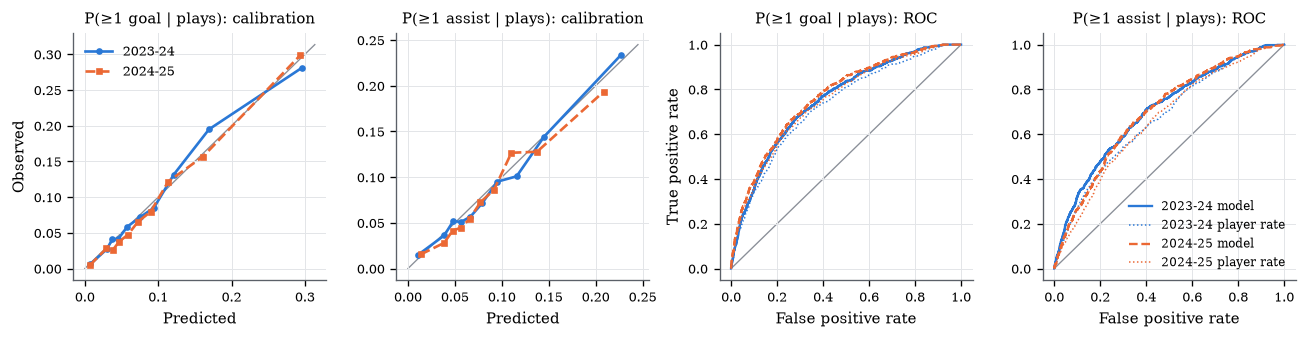

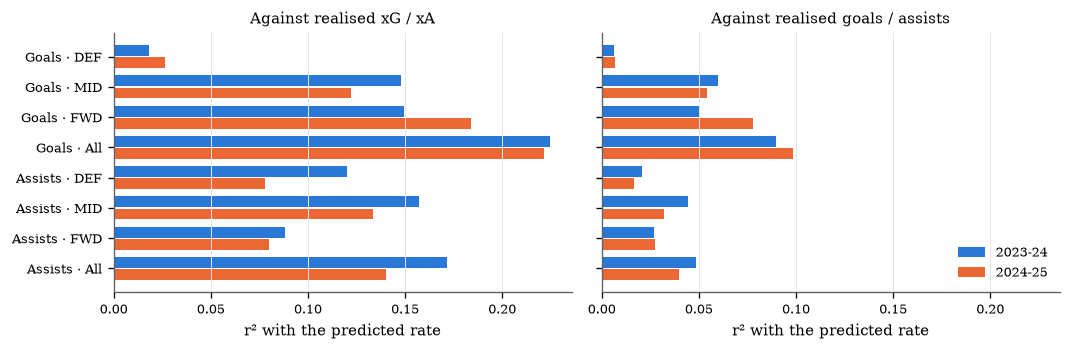

In [15]:
# Figure: calibration of P(at least one goal / assist | plays), and the ROC curves against the player-rate baseline
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for season, x in played.items():
    for j, (k, (count, _, name)) in enumerate(EVENTS.items()):
        hit = (x[count] >= 1).astype(int)
        p = 1 - np.exp(-x[f"rate_{k}"])
        b = pd.qcut(p.rank(method="first"), 10, labels=False)
        cal = pd.DataFrame({"p": p, "y": hit}).groupby(b).mean()
        axes[j].plot(cal["p"], cal["y"], color=SEASON_COLOR[season], label=f"20{season}", **SEASON_STYLE[season])
        fpr, tpr, _ = roc_curve(hit, p)
        axes[2 + j].plot(fpr, tpr, color=SEASON_COLOR[season], lw=1.4, ls=SEASON_STYLE[season]["ls"],
                         label=f"20{season} model")
        fpr, tpr, _ = roc_curve(hit, 1 - np.exp(-x[f"base_{k}"]))
        axes[2 + j].plot(fpr, tpr, color=SEASON_COLOR[season], lw=0.9, ls=":", label=f"20{season} player rate")
for j, name in enumerate(["goal", "assist"]):
    lim = [0, max(axes[j].get_xlim()[1], axes[j].get_ylim()[1])]
    axes[j].plot(lim, lim, color=GREY, lw=0.8, zorder=0)
    axes[j].set_title(f"P(≥1 {name} | plays): calibration")
    axes[j].set_xlabel("Predicted")
    axes[2 + j].plot([0, 1], [0, 1], color=GREY, lw=0.8, zorder=0)
    axes[2 + j].set_title(f"P(≥1 {name} | plays): ROC")
    axes[2 + j].set_xlabel("False positive rate")
axes[0].set_ylabel("Observed")
axes[2].set_ylabel("True positive rate")
axes[0].legend(loc="upper left")
axes[3].legend(loc="lower right", fontsize=7)
fig.tight_layout()
save(fig, "structural_events")
plt.show()

# Figure: how much of the variation the predicted rate explains, in realised xG/xA and in realised goals/assists
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), sharey=True, sharex=True)
labels = [f"{e} · {p}" for e in ["Goals", "Assists"] for p in ["DEF", "MID", "FWD", "All"]][::-1]
y = np.arange(len(labels))
h = 0.36
for ax, col, title in zip(axes, ["r² with realised xG/xA", "r² with realised count"],
                          ["Against realised xG / xA", "Against realised goals / assists"]):
    for k, season in enumerate(SEASONS):
        v = [xg_check.loc[(season, l.split(" · ")[0], l.split(" · ")[1]), col] for l in labels]
        ax.barh(y + (h / 2 + 0.02) * (1 if k == 0 else -1), v, height=h, color=SEASON_COLOR[season],
                label=f"20{season}")
    ax.set_title(title)
    ax.set_xlabel("r² with the predicted rate")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, labels)
axes[1].legend(loc="lower right")
fig.tight_layout()
save(fig, "structural_xg_check")
plt.show()


## 8. Summary

Gameweeks 5-38, every player-fixture (27,084 in 2023-24, 24,733 in 2024-25). The totals (RMSE 1.850 and 1.871) are
within 0.004 of the structural README's.

* **Every component is about right on average.** Over all players, appearance, clean sheet, goals conceded, goals,
  assists and bonus agree with their actual means within 5% in 2023-24 and within 7% in 2024-25. Saves and other
  (few events) are off by 6-12%. The total is within 0.3% and 2%. The largest position-level gaps: MID clean
  sheets are under-predicted by 14-16% (the known effect of treating a player on for 60+ as on for the whole match),
  FWD assists in 2024-25 are over-predicted by 20%, and FWD bonus is +16% in 2023-24 and −9% in 2024-25.
* **Playing time is predicted very well, and it carries most of the model's skill.** P(plays) and P(60+) are
  calibrated (the curves sit on the diagonal) with AUC 0.95-0.96 and a third of the base-rate Brier score.
  Appearance points have R² 0.70-0.71 and beat the player's season-mean baseline by 36-42%.
* **The match events are mostly noise at this level.** R² is 0.29-0.45 for saves and goals conceded, 0.17 for clean
  sheets, about 0.11 for goals, 0.07-0.10 for assists and bonus, and 0.05-0.07 for other. Every component still beats
  the baseline (skill 0.06-0.18), and so does the total (0.13-0.15).
* **Goals, clean sheets and bonus make up most of the error.** Goals are 36-38% of the total error variance (about
  half for MID and FWD), clean sheets 16-18% (45-47% for GK, 36-42% for DEF), bonus 17% and assists 13%. Appearance is
  only 10-11%, and saves, goals conceded and other are 1-2% each. Better minutes prediction has little room left; the
  remaining error is in whether the goal or the clean sheet happens.
* **The team model separates games only weakly.** Its λ is calibrated (P(0) and P(4+) goals match the observed rates)
  but explains 10-12% of the deviance, and the clean-sheet probability has AUC 0.65-0.67, a little better than the
  base rate (Brier 0.157 vs 0.166, 0.171 vs 0.180).
* **Given that the player plays, the components are calibrated too,** including their top deciles (goals: 1.60
  predicted vs 1.59 scored in 2023-24, 1.58 vs 1.49 in 2024-25; clean sheet 1.25-1.28 vs 1.25-1.28). The saves and
  other curves are noisy (few goalkeepers, rare events): saves' top decile is under-predicted in 2023-24 (1.10 vs 1.29)
  and over-predicted in 2024-25 (1.20 vs 1.00).
* **On their own events, the goal and assist models are calibrated and beat a player's own record.** Given that he
  plays, P(at least one goal) is 0.093 predicted vs 0.094 observed (2023-24) and 0.091 vs 0.087 (2024-25); assists
  0.088 vs 0.086 and 0.085 vs 0.079. AUC is 0.75-0.77 for goals and 0.70-0.71 for assists, against 0.73-0.75 and
  0.66-0.67 for the player's season-to-date rate (shrunk to his position's), and the model has the lower Brier score,
  log loss and Poisson deviance than both that baseline and the overall rate in both seasons. The margins are small
  (goals Brier 0.078 vs 0.079 vs 0.085 in 2023-24).
* **The limit is mostly finishing, not the model.** The predicted goal rate explains 22% of the variation in the
  player's realised xG but only 9-10% of his realised goals, and realised xG itself explains only 37-40% of goals.
  For assists: 14-17% of realised xA, 4-5% of assists, and xA explains 13-15% of assists. Defenders' goal rate
  explains 2-3% of their xG: their goals (set pieces) are the least predictable.

**Figures** (`working/figures/`, PDF): `structural_level` (predicted / actual by component and position),
`structural_accuracy` (R² and skill), `structural_error_share` (share of the error variance), `structural_probabilities`
(calibration of P(plays), P(60+), the clean sheet and λ), `structural_conditional_calibration` (each component given
that the player plays), `structural_events` (calibration and ROC of P(≥1 goal) and P(≥1 assist)), `structural_xg_check`
(the predicted rate against realised xG/xA and goals/assists).